
# RQ1 Walkthrough — Qualitative Inspection of the Winning Retrieval Pipeline

This notebook is a **qualitative companion** to the quantitative RQ1 evaluation in `01_rq1_chunking_evaluation.ipynb`. Its purpose is not to re-run the full 54-configuration experiment, but to make the selected retrieval pipeline **transparent and reproducible** by tracing its behaviour on a single, representative question–company pair.

---

### Motivation

The quantitative RQ1 notebook answers *which* configuration wins; this walkthrough answers *why* it wins and *how* each retrieval stage contributes. By following one concrete sample through every pipeline stage — chunking, dense retrieval, sparse retrieval, fusion, and cross-encoder reranking — the reader builds an intuitive understanding of the mechanics behind the aggregate metrics.

### What This Notebook Shows

1. **Winner verification** — which configuration won RQ1 under the predefined primary metric (`Recall@15`) and the budget-normalized alternative (`Budgeted Recall@4096`).
2. **Gold evidence** — the exact expert-annotated passages that retrieval is expected to surface.
3. **Chunking inspection** — how the winning chunking strategy segments the sustainability report around the evidence region.
4. **Stage-by-stage retrieval** — how ranking evolves from `dense` → `sparse` → `hybrid_rrf` → `hybrid_rerank`, with per-stage metrics.
5. **Ranking shift visualization** — how individual chunks move through the ranking across retrieval stages.
6. **Budget-normalized comparison** — how the primary winner and the budget-normalized winner perform on the same sample.

> **Thesis caveat:** this notebook illustrates *how* the chosen pipeline behaves on one sample. The statistical justification for the final RQ1 conclusion — including bootstrap confidence intervals, permutation tests, and Holm–Bonferroni correction — remains in the full evaluation notebook (`01_rq1_chunking_evaluation.ipynb`).

### Notebook Structure

| Section | Content |
|---|---|
| 1 | Corpus context and RQ1 winner verification |
| 2 | Sample selection and gold evidence display |
| 3 | Notebook-local helpers for faithful offline reconstruction |
| 4 | Chunking behaviour of the winning pipeline |
| 5 | Stage-by-stage retrieval with per-stage metrics |
| 6 | Retrieved evidence, coverage table, and ranking shift plot |
| 7 | Compact comparison with the budget-normalized winner |
| 8 | Interpretation and methodological notes |



## 1. Corpus Context and RQ1 Winner

Before inspecting a single example, we load the persisted RQ1 artifacts and verify that they match the current pipeline fingerprint (`results_version`). We then display the **primary winner** (selected by `Recall@15`) and the **budget-normalized winner** (selected by `Budgeted Recall@4096`).

This distinction is important for interpretation: the walkthrough centres on the primary winner because RQ2 and RQ3 inherit the pipeline selected by the predeclared primary metric, while still acknowledging the budget-normalized trade-off that may be relevant in token-constrained deployment scenarios.


In [1]:
# ---------------------------------------------------------------------------
# Imports, paths, plotting defaults, and RQ1 artifact context
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
import json
import hashlib
import mmap
import re
from textwrap import shorten

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rag.config.settings import PipelineConfig, RQ1_RESULTS_DIR, RQ1_RESULTS_VERSION
from rag.data.loaders import load_reports, load_golden_samples
from rag.data.text_utils import normalize_text
from rag.chunking.strategies import build_chunks_for_config
from rag.retrieval.methods import Retriever
from rag.evaluation.metrics import _compute_for_sample, _is_relevant

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

results_csv = RQ1_RESULTS_DIR / "rq1_config_results.csv"
winner_json = RQ1_RESULTS_DIR / "rq1_winner.json"

df = pd.read_csv(results_csv)
winner_payload = json.loads(winner_json.read_text(encoding="utf-8"))

assert len(df) == 54, f"Expected 54 configurations, found {len(df)}"
assert set(df["results_version"].dropna().astype(str)) == {RQ1_RESULTS_VERSION}, (
    "Persisted RQ1 results do not match the current pipeline fingerprint. "
    "Re-run RQ1 before interpreting this notebook."
)

rank_primary = df.sort_values("recall@15", ascending=False).reset_index(drop=True)
rank_budget = df.sort_values("budgeted_recall@4096", ascending=False).reset_index(drop=True)
primary_winner = rank_primary.iloc[0]
budget_winner = rank_budget.iloc[0]

summary_df = pd.DataFrame([
    {
        "Selection": "Primary metric winner",
        "Config": primary_winner["config_id"],
        "Recall@15": round(primary_winner["recall@15"], 4),
        "Precision@15": round(primary_winner["precision@15"], 4),
        "MRR@10": round(primary_winner["mrr@10"], 4),
        "Budgeted Recall@4096": round(primary_winner["budgeted_recall@4096"], 4),
    },
    {
        "Selection": "Budget-normalized winner",
        "Config": budget_winner["config_id"],
        "Recall@15": round(budget_winner["recall@15"], 4),
        "Precision@15": round(budget_winner["precision@15"], 4),
        "MRR@10": round(budget_winner["mrr@10"], 4),
        "Budgeted Recall@4096": round(budget_winner["budgeted_recall@4096"], 4),
    },
])

print(f"Project root        : {PROJECT_ROOT}")
print(f"Results version     : {RQ1_RESULTS_VERSION}")
print(f"Primary RQ1 winner  : {winner_payload['config_id']}")
print(f"Budget winner       : {budget_winner['config_id']}")
display(summary_df)

Project root        : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
Results version     : index=1d84703f3f;eval=e368f1561a;rerank=2a2e612de0
Primary RQ1 winner  : fixed_1024_hybrid_rerank
Budget winner       : semantic_512_hybrid_rerank


,Selection,Config,Recall@15,Precision@15,MRR@10,Budgeted Recall@4096
0,Primary metric winner,fixed_1024_hybrid_rerank,0.9616,0.3288,0.8324,0.7672
1,Budget-normalized winner,semantic_512_hybrid_rerank,0.8867,0.2101,0.7416,0.8438



## 2. Sample Selection and Gold Evidence

The walkthrough uses a single question–company pair: **Eni / Q1 (ESRS 2 — General Disclosures)**.

This sample was chosen for this reason:

| Criterion | Why it matters |
|---|---|
| **Conceptually central question** | Q1 concerns the **double materiality assessment** — a core ESRS concept — so the evidence is thematically representative of real regulatory queries. |


The table below shows the exact evidence passages that the retrieval pipeline is expected to surface. Each passage was manually annotated in the Golden Standard with a `passage_id`, source page, and section header.


In [2]:
# ---------------------------------------------------------------------------
# Load reports and golden samples, then select the walkthrough sample.
# ---------------------------------------------------------------------------
reports = load_reports()
samples = load_golden_samples()

SAMPLE_COMPANY = "Eni"
SAMPLE_QUESTION_ID = "Q1"
SAMPLE = next(s for s in samples if s.company == SAMPLE_COMPANY and s.question_id == SAMPLE_QUESTION_ID)

assert SAMPLE.esrs_standard == "ESRS 2", f"Expected ESRS 2, got {SAMPLE.esrs_standard}"
assert len(SAMPLE.evidences) == 3, f"Expected 3 gold evidences, found {len(SAMPLE.evidences)}"

winner_details = json.loads((RQ1_RESULTS_DIR / "config_details" / f"{winner_payload['config_id']}.json").read_text())
budget_details = json.loads((RQ1_RESULTS_DIR / "config_details" / f"{budget_winner['config_id']}.json").read_text())

winner_sample_metrics = next(
    row for row in winner_details["details"]["per_sample_metrics"]
    if row["company"] == SAMPLE_COMPANY and row["question_id"] == SAMPLE_QUESTION_ID
)
budget_sample_metrics = next(
    row for row in budget_details["details"]["per_sample_metrics"]
    if row["company"] == SAMPLE_COMPANY and row["question_id"] == SAMPLE_QUESTION_ID
)

print(f"Company       : {SAMPLE.company}")
print(f"Question ID   : {SAMPLE.question_id}")
print(f"ESRS standard : {SAMPLE.esrs_standard}")
print(f"Question      : {SAMPLE.question}")

gold_df = pd.DataFrame([
    {
        "passage_id": ev.passage_id,
        "page": ev.page_number,
        "section_header": ev.source_section_header,
        "gold_preview": shorten(ev.text.replace("\n", " "), width=240, placeholder="..."),
    }
    for ev in SAMPLE.evidences
])

gold_df

Company       : Eni
Question ID   : Q1
ESRS standard : ESRS 2
Question      : How has the undertaking conducted its double materiality assessment, and which sustainability matters were identified as material from both an impact and a financial perspective?


,passage_id,page,section_header,gold_preview
0,ENI_Q1_E1,135,Process and Results of the Double Materiality ...,"The 2024 materiality assessment, aimed to iden..."
1,ENI_Q1_E2,136-137,Process and Results of the Double Materiality ...,"For the impact materiality, the assessment was..."
2,ENI_Q1_E3,138-139,Material Issues for Eni and its Stakeholders,Impact materiality: Climate change: actual cli...



## 3. Notebook-Local Helpers for Faithful Reconstruction

The full RQ1 experiment indexed embeddings in Qdrant and cached them to disk. For this walkthrough, we reconstruct the same dense retrieval stage directly from the **persisted OpenAI embedding cache** (`embedding_cache.json`), which avoids live API calls while preserving the exact same retrieval signal.


In [3]:
# ---------------------------------------------------------------------------
# Notebook-local helpers: config parsing, cache-backed embeddings,
# in-memory dense index, hit annotation, and sample metric helpers.
# ---------------------------------------------------------------------------
EMBEDDING_CACHE_PATH = PROJECT_ROOT / "data" / "artifacts" / "embedding_cache.json"
MODEL_NAME = "text-embedding-3-large"
_PAGE_RE = re.compile(r"<!--\s*Report Page\s+\d+\s*-->")
REPORT_TEXT_BY_COMPANY = {
    SAMPLE_COMPANY: normalize_text(_PAGE_RE.sub("", reports[SAMPLE_COMPANY].raw_text))
}


def parse_config_id(config_id: str) -> PipelineConfig:
    parts = config_id.split("_")
    strategy = parts[0] if parts[0] != "structure" else "structure_aware"
    if strategy == "structure_aware":
        size = int(parts[2])
        method = "_".join(parts[3:])
    else:
        size = int(parts[1])
        method = "_".join(parts[2:])
    return PipelineConfig(chunk_strategy=strategy, chunk_size=size, retrieval_method=method)


def embedding_cache_key(text: str, model: str = MODEL_NAME) -> str:
    return hashlib.sha1(f"{model}:{text}".encode("utf-8")).hexdigest()


def _extract_json_array(mm: mmap.mmap, start: int) -> list[float]:
    depth = 0
    end = start
    while end < mm.size():
        b = mm[end:end + 1]
        if b == b"[":
            depth += 1
        elif b == b"]":
            depth -= 1
            if depth == 0:
                end += 1
                break
        end += 1
    return json.loads(mm[start:end].decode("utf-8"))


def extract_vector_from_cache(text: str) -> list[float]:
    sha = embedding_cache_key(text)
    needle = f'"{sha}":'.encode("utf-8")
    with EMBEDDING_CACHE_PATH.open("rb") as f:
        mm = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)
        pos = mm.find(needle)
        if pos < 0:
            mm.close()
            raise RuntimeError(
                "Required embedding is missing from embedding_cache.json and no live API fallback is allowed in this notebook."
            )
        start = mm.find(b"[", pos)
        vec = _extract_json_array(mm, start)
        mm.close()
        return vec


def extract_vectors_in_order(texts: list[str]) -> list[list[float]]:
    wanted = [embedding_cache_key(text) for text in texts]
    found: dict[str, list[float]] = {}
    with EMBEDDING_CACHE_PATH.open("rb") as f:
        mm = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)
        pos = 0
        for sha in wanted:
            needle = f'"{sha}":'.encode("utf-8")
            found_pos = mm.find(needle, pos)
            if found_pos < 0:
                found_pos = mm.find(needle, 0)
            if found_pos < 0:
                mm.close()
                raise RuntimeError(
                    "One or more chunk embeddings are missing from embedding_cache.json. "
                    "This notebook does not permit silent fallback embeddings."
                )
            start = mm.find(b"[", found_pos)
            found[sha] = _extract_json_array(mm, start)
            pos = found_pos + 1
        mm.close()
    return [found[sha] for sha in wanted]


class CacheOnlyEmbedder:
    """Return only persisted OpenAI embeddings; never fall back silently."""

    def __init__(self, model: str = MODEL_NAME, dims: int = 3072) -> None:
        self.model = model
        self.dims = dims

    def embed_text(self, text: str) -> list[float]:
        return extract_vector_from_cache(text)


class InMemoryDenseIndex:
    """Cosine search over cached chunk vectors for one notebook sample.

    The full RQ1 experiment stored the same vectors in Qdrant. For this
    walkthrough we reconstruct dense search directly from the persisted
    vectors for the selected report, which keeps the notebook portable and
    deterministic without changing the underlying retrieval signal.
    """

    def __init__(self, chunks, vectors) -> None:
        self.chunk_ids = [c.chunk_id for c in chunks]
        arr = np.asarray(vectors, dtype=np.float64)
        norms = np.linalg.norm(arr, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        self.vectors = arr / norms

    @staticmethod
    def collection_name(strategy: str, size: int) -> str:
        return f"in_memory_{strategy}_{size}"

    def search(self, collection_name: str, query_vector: list[float], top_k: int, company: str | None = None):
        query = np.asarray(query_vector, dtype=np.float64)
        q_norm = np.linalg.norm(query) or 1.0
        scores = self.vectors @ (query / q_norm)
        order = np.argsort(-scores)[:top_k]
        return [(self.chunk_ids[i], float(scores[i]), {}) for i in order]


def sample_metrics_from_hits(hits: list) -> dict[str, float]:
    return _compute_for_sample(
        hits,
        SAMPLE,
        REPORT_TEXT_BY_COMPANY,
        chunk_span_cache={},
        gold_span_cache={},
    )


def matched_evidence_ids(chunk) -> list[str]:
    matched = []
    for ev in SAMPLE.evidences:
        if _is_relevant(
            chunk,
            ev,
            REPORT_TEXT_BY_COMPANY,
            chunk_span_cache={},
            gold_span_cache={},
        ):
            matched.append(ev.passage_id)
    return matched


def _clean_preview(text: str, width: int = 150) -> str:
    """Produce a clean, human-readable text preview for display tables."""
    clean = re.sub(r"\s+", " ", text.replace("\n", " ")).strip()
    # Strip leading markdown artifacts (headers, pipes, bullets)
    clean = re.sub(r"^[#|>*\-\s]+", "", clean).strip()
    return shorten(clean, width=width, placeholder=" ...")


def hits_to_df(hits: list, method_label: str, top_n: int = 8) -> pd.DataFrame:
    rows = []
    for hit in hits[:top_n]:
        matched = matched_evidence_ids(hit.chunk)
        rows.append({
            "method": method_label,
            "rank": hit.rank,
            "pages": f"{hit.chunk.page_start}-{hit.chunk.page_end}",
            "tokens": hit.chunk.token_count,
            "relevant": "yes" if matched else "",
            "score": round(float(hit.score), 4),
            "text_preview": _clean_preview(hit.chunk.text),
        })
    return pd.DataFrame(rows)


def coverage_table(method_to_hits: dict[str, list]) -> pd.DataFrame:
    rows = []
    for ev in SAMPLE.evidences:
        row = {
            "passage_id": ev.passage_id,
            "page": ev.page_number,
            "section_header": ev.source_section_header,
        }
        for method, hits in method_to_hits.items():
            first_rank = None
            for hit in hits:
                if ev.passage_id in matched_evidence_ids(hit.chunk):
                    first_rank = hit.rank
                    break
            row[method] = first_rank if first_rank is not None else "not in top-15"
        rows.append(row)
    return pd.DataFrame(rows)


def config_metrics_from_artifact(config_id: str) -> dict[str, float]:
    payload = json.loads((RQ1_RESULTS_DIR / "config_details" / f"{config_id}.json").read_text())
    return next(
        row for row in payload["details"]["per_sample_metrics"]
        if row["company"] == SAMPLE_COMPANY and row["question_id"] == SAMPLE_QUESTION_ID
    )

## 4. Chunking Behaviour of the Winning Pipeline

The winning RQ1 pipeline uses **fixed-size chunking with a 1 024-token ceiling** and 12.5% overlap between consecutive windows. This section answers two practical questions before retrieval begins:

1. **Corpus size** — how many chunks does the Eni report produce under both the primary winner and the budget-normalized winner?
2. **Evidence locality** — which chunk windows surround the gold evidence page range for this sample?

The preview below selects chunks by **page-span overlap with the gold evidence pages** rather than by the full relevance matcher. This keeps the chunking illustration intuitive — the formal relevance matching is applied in the retrieval sections that follow.


In [4]:
# ---------------------------------------------------------------------------
# Build winner and budget-winner chunks for the selected report.
# ---------------------------------------------------------------------------
WINNER_CONFIG = parse_config_id(winner_payload["config_id"])
BUDGET_CONFIG = parse_config_id(budget_winner["config_id"])

winner_chunks, winner_stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, WINNER_CONFIG)
budget_chunks, budget_stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, BUDGET_CONFIG)

chunk_compare_df = pd.DataFrame([
    {
        "Configuration": winner_payload["config_id"],
        "Strategy": WINNER_CONFIG.chunk_strategy,
        "Chunk size": WINNER_CONFIG.chunk_size,
        f"Total chunks ({SAMPLE_COMPANY} only)": winner_stats.total_chunks,
        "Mean tokens": round(winner_stats.mean_tokens, 1),
        "Median tokens": round(winner_stats.median_tokens, 1),
        "Max tokens": winner_stats.max_tokens,
    },
    {
        "Configuration": budget_winner["config_id"],
        "Strategy": BUDGET_CONFIG.chunk_strategy,
        "Chunk size": BUDGET_CONFIG.chunk_size,
        f"Total chunks ({SAMPLE_COMPANY} only)": budget_stats.total_chunks,
        "Mean tokens": round(budget_stats.mean_tokens, 1),
        "Median tokens": round(budget_stats.median_tokens, 1),
        "Max tokens": budget_stats.max_tokens,
    },
])


def parse_page_span(page_value: str) -> set[int]:
    pages = set()
    for part in str(page_value).split(","):
        part = part.strip()
        if not part:
            continue
        if "-" in part:
            start, end = part.split("-", 1)
            pages.update(range(int(start), int(end) + 1))
        else:
            pages.add(int(part))
    return pages


gold_pages = sorted(set().union(*[parse_page_span(ev.page_number) for ev in SAMPLE.evidences]))


def chunks_near_gold_pages(chunks: list) -> pd.DataFrame:
    rows = []
    for chunk in chunks:
        if chunk.page_start is None or chunk.page_end is None:
            continue
        chunk_pages = set(range(chunk.page_start, chunk.page_end + 1))
        overlap = sorted(chunk_pages & set(gold_pages))
        if not overlap:
            continue
        rows.append({
            "chunk_id": chunk.chunk_id[:12],
            "pages": f"{chunk.page_start}-{chunk.page_end}",
            "tokens": chunk.token_count,
            "gold_pages_intersected": ", ".join(map(str, overlap)),
            "text_preview": _clean_preview(chunk.text),
        })
    return pd.DataFrame(rows)


print("Chunk statistics for the selected report:")
display(chunk_compare_df)
print(f"\nGold evidence pages for the sample: {gold_pages}")
print("Winner chunks whose page spans intersect the gold evidence pages:")
display(chunks_near_gold_pages(winner_chunks).head(6))

Chunk statistics for the selected report:


,Configuration,Strategy,Chunk size,Total chunks (Eni only),Mean tokens,Median tokens,Max tokens
0,fixed_1024_hybrid_rerank,fixed,1024,148,1022.5,1024,1026
1,semantic_512_hybrid_rerank,semantic,512,403,340.6,378,513



Gold evidence pages for the sample: [135, 136, 137, 138, 139]
Winner chunks whose page spans intersect the gold evidence pages:


,chunk_id,pages,tokens,gold_pages_intersected,text_preview
0,90c26bb407c0,132-135,1023,135,Sustainability Statement ## LEGEND | General i...
1,ea360adcaeed,134-136,1024,"135, 136",along with the mitigation actions. The Sustain...
2,218c6ae6f139,136-137,1024,"136, 137",highest level of which is associated with oppo...
3,13b31d5e7a14,137-139,1024,"137, 138, 139",business activities about material impacts and...
4,66f171399707,138-140,1024,"138, 139",. Financial materiality Risks: climate change ...



## 5. Stage-by-Stage Retrieval in the Winning Pipeline

The winning configuration is `fixed_1024_hybrid_rerank`. This pipeline is composed of four retrieval stages, each adding a complementary signal:

| Stage | Method | Signal type |
|---|---|---|
| 1 | **Dense** | Semantic similarity via OpenAI `text-embedding-3-large` (cosine search) |
| 2 | **Sparse (BM25)** | Lexical overlap with Okapi BM25 (k₁=1.5, b=0.75) |
| 3 | **Hybrid RRF** | Reciprocal Rank Fusion combining dense + sparse rankings (k=60) |
| 4 | **Hybrid + Rerank** | Cross-encoder reranking of the fused candidate set (`ms-marco-MiniLM-L-6-v2`) |

The code below reconstructs the winner's chunk embeddings from the persisted cache, runs all four stages on the selected sample, and computes per-stage metrics. The second table cross-checks the reconstructed metrics against the persisted RQ1 evaluation artifact to confirm faithful reproduction.


In [5]:
# ---------------------------------------------------------------------------
# Reconstruct the winning retrieval pipeline from cached embeddings.
# ---------------------------------------------------------------------------
winner_chunk_vectors = extract_vectors_in_order([chunk.retrieval_text for chunk in winner_chunks])
cache_embedder = CacheOnlyEmbedder()
dense_index = InMemoryDenseIndex(winner_chunks, winner_chunk_vectors)

method_order = ["dense", "sparse", "hybrid_rrf", "hybrid_rerank"]
method_to_hits = {}
method_metric_rows = []

for method in method_order:
    cfg = PipelineConfig(
        chunk_strategy=WINNER_CONFIG.chunk_strategy,
        chunk_size=WINNER_CONFIG.chunk_size,
        retrieval_method=method,
        top_k=15,
    )
    retriever = Retriever(
        chunks=winner_chunks,
        config=cfg,
        embedder=cache_embedder,
        qdrant=dense_index,
    )
    hits = retriever.retrieve(SAMPLE.question, company=SAMPLE_COMPANY, top_k=15)
    method_to_hits[method] = hits
    metrics = sample_metrics_from_hits(hits)
    method_metric_rows.append({
        "Method": method,
        "Recall@5": round(metrics["recall@5"], 4),
        "Recall@10": round(metrics["recall@10"], 4),
        "Recall@15": round(metrics["recall@15"], 4),
        "Precision@15": round(metrics["precision@15"], 4),
        "MRR@10": round(metrics["mrr@10"], 4),
        "Budgeted Recall@4096": round(metrics["budgeted_recall@4096"], 4),
    })

method_metrics_df = pd.DataFrame(method_metric_rows)
print(f"Sample-level metrics for {SAMPLE_COMPANY} / {SAMPLE_QUESTION_ID} under the winner chunking configuration:")
display(method_metrics_df)

print("Persisted artifact metrics for the final winning method on this sample:")
display(pd.DataFrame([{
    k: round(winner_sample_metrics[k], 4)
    for k in ["recall@5", "recall@10", "recall@15", "precision@15", "mrr@10", "budgeted_recall@4096"]
}]))

Sample-level metrics for Eni / Q1 under the winner chunking configuration:


,Method,Recall@5,Recall@10,Recall@15,Precision@15,MRR@10,Budgeted Recall@4096
0,dense,0.6667,1.0000,1.0000,0.2000,1.0,0.6667
1,sparse,0.6667,0.6667,0.6667,0.1333,1.0,0.6667
2,hybrid_rrf,0.6667,1.0000,1.0000,0.2000,1.0,0.6667
3,hybrid_rerank,1.0000,1.0000,1.0000,0.2000,1.0,0.6667


Persisted artifact metrics for the final winning method on this sample:


,recall@5,recall@10,recall@15,precision@15,mrr@10,budgeted_recall@4096
0,1.0,1.0,1.0,0.2,1.0,0.6667



## 6. Retrieved Evidence and Ranking Shifts

This section makes the abstract metrics from Section 5 concrete by inspecting the actual retrieved passages:

- **Top-8 retrieved chunks per stage** — the passages each method surfaces, with their scores and relevance annotations.
- **Coverage table** — the first rank at which each of the three gold evidence passages appears, per retrieval method.
- **Ranking shift plot** — a bump chart showing how the same chunks move up or down through the ranking across the four retrieval stages. Chunks that appear in the top-15 of at least one method are tracked; a rank of 16 indicates the chunk was not retrieved in that stage's top-15.

Together, these outputs illustrate the **complementary contributions** of semantic matching (dense), keyword matching (sparse), fusion (RRF), and fine-grained reranking (cross-encoder). In this sample, sparse retrieval fails to surface one evidence passage entirely, making the compensating role of dense retrieval, fusion, and reranking especially visible in the ranking shifts.



  DENSE


,method,rank,pages,tokens,relevant,score,text_preview
0,dense,1,134-136,1024,yes,0.6773,along with the mitigation actions. The Sustain...
1,dense,2,136-137,1024,yes,0.6220,highest level of which is associated with oppo...
2,dense,3,132-135,1023,,0.5943,Sustainability Statement ## LEGEND | General i...
3,dense,4,138-140,1024,,0.5785,. Financial materiality Risks: climate change ...
4,dense,5,252-254,1024,,0.5667,or on behalf of or in the interest of Eni - th...
5,dense,6,137-139,1024,yes,0.5635,business activities about material impacts and...
6,dense,7,258-259,1026,,0.5550,principles and criteria: Metrics: methodologie...
7,dense,8,253-255,1024,,0.5536,Information: Basis for preparation Reporting p...



  SPARSE


,method,rank,pages,tokens,relevant,score,text_preview
0,sparse,1,134-136,1024,yes,29.5611,along with the mitigation actions. The Sustain...
1,sparse,2,252-254,1024,,25.8202,or on behalf of or in the interest of Eni - th...
2,sparse,3,136-137,1024,yes,24.9849,highest level of which is associated with oppo...
3,sparse,4,138-140,1024,,19.6190,. Financial materiality Risks: climate change ...
4,sparse,5,172-174,1024,,18.0429,", the relevance of these dependencies varies a..."
5,sparse,6,147-148,1024,,17.8632,", Eni promotes combined multisectoral and glob..."
6,sparse,7,152-152,1024,,17.1542,the cases where a high level of residual risk ...
7,sparse,8,175-176,1024,,17.0023,both the environment and society. ### TARGETS ...



  HYBRID_RRF


,method,rank,pages,tokens,relevant,score,text_preview
0,hybrid_rrf,1,134-136,1024,yes,0.0328,along with the mitigation actions. The Sustain...
1,hybrid_rrf,2,136-137,1024,yes,0.0320,highest level of which is associated with oppo...
2,hybrid_rrf,3,252-254,1024,,0.0315,or on behalf of or in the interest of Eni - th...
3,hybrid_rrf,4,138-140,1024,,0.0312,. Financial materiality Risks: climate change ...
4,hybrid_rrf,5,132-135,1023,,0.0294,Sustainability Statement ## LEGEND | General i...
5,hybrid_rrf,6,137-139,1024,yes,0.0278,business activities about material impacts and...
6,hybrid_rrf,7,147-148,1024,,0.0269,", Eni promotes combined multisectoral and glob..."
7,hybrid_rrf,8,218-219,1024,,0.0267,those relating to actions and targets are expl...



  HYBRID_RERANK


,method,rank,pages,tokens,relevant,score,text_preview
0,hybrid_rerank,1,134-136,1024,yes,0.9750,along with the mitigation actions. The Sustain...
1,hybrid_rerank,2,136-137,1024,yes,0.9086,highest level of which is associated with oppo...
2,hybrid_rerank,3,138-140,1024,,0.8540,. Financial materiality Risks: climate change ...
3,hybrid_rerank,4,132-135,1023,,0.7483,Sustainability Statement ## LEGEND | General i...
4,hybrid_rerank,5,137-139,1024,yes,0.7270,business activities about material impacts and...
5,hybrid_rerank,6,252-254,1024,,0.6804,or on behalf of or in the interest of Eni - th...
6,hybrid_rerank,7,140-141,1024,,0.6509,internal specialist functions that deal with p...
7,hybrid_rerank,8,147-148,1024,,0.6388,", Eni promotes combined multisectoral and glob..."



First rank at which each gold evidence passage is retrieved:


,passage_id,page,section_header,dense,sparse,hybrid_rrf,hybrid_rerank
0,ENI_Q1_E1,135,Process and Results of the Double Materiality ...,1,1,1,1
1,ENI_Q1_E2,136-137,Process and Results of the Double Materiality ...,1,1,1,1
2,ENI_Q1_E3,138-139,Material Issues for Eni and its Stakeholders,6,not in top-15,6,5


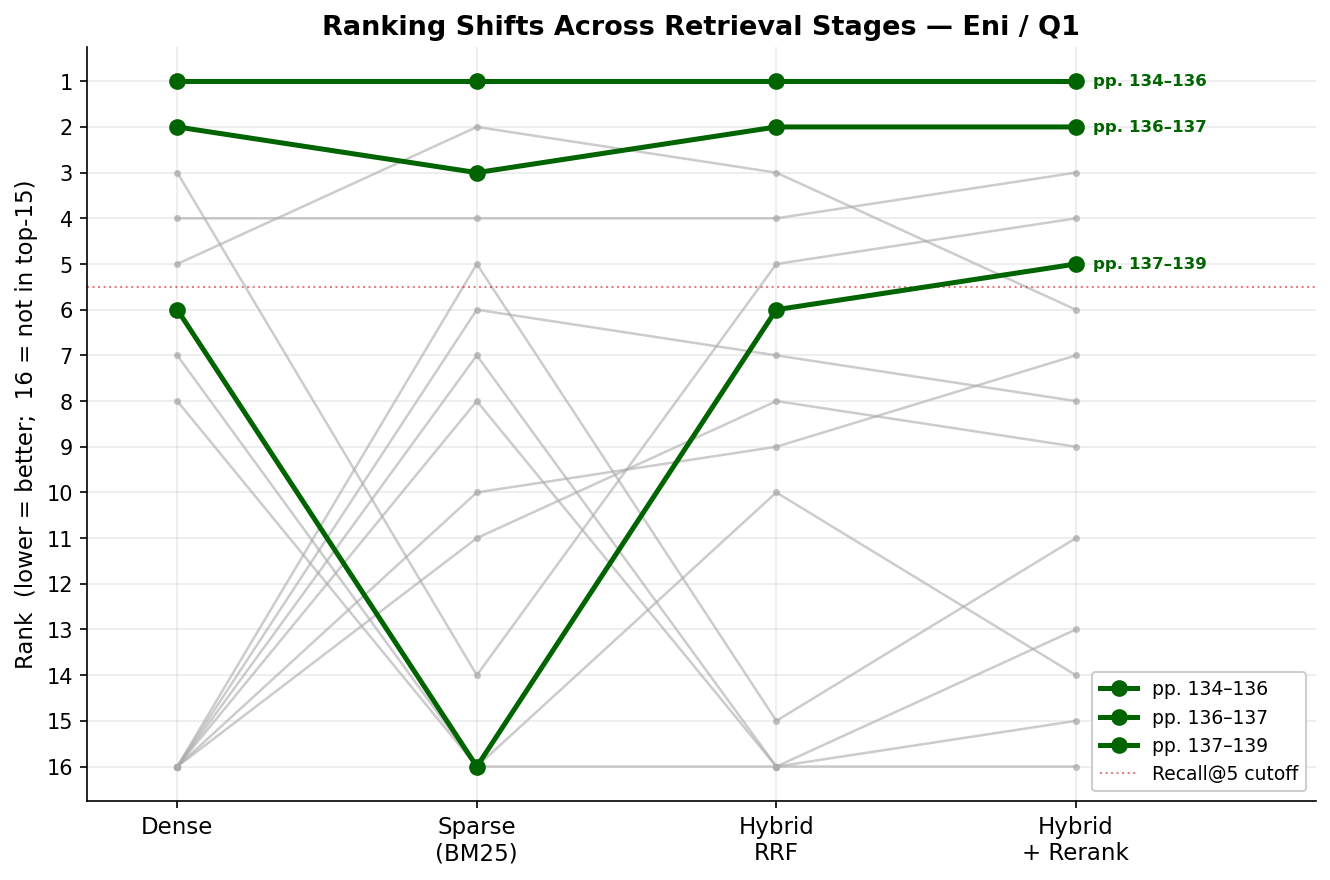

In [6]:
# ---------------------------------------------------------------------------
# Display retrieved chunks per stage and visualise rank shifts.
# ---------------------------------------------------------------------------
for method in method_order:
    print("\n" + "=" * 96)
    print(f"  {method.upper()}")
    print("=" * 96)
    display(hits_to_df(method_to_hits[method], method_label=method, top_n=8))

print("\nFirst rank at which each gold evidence passage is retrieved:")
display(coverage_table(method_to_hits))

# ── Build rank-shift data for the bump chart ──
rank_maps = {
    method: {hit.chunk.chunk_id[:12]: hit.rank for hit in hits}
    for method, hits in method_to_hits.items()
}

# Track chunks that appear in the top-8 of at least one stage.
focus_ids = []
for method in method_order:
    focus_ids.extend([hit.chunk.chunk_id[:12] for hit in method_to_hits[method][:8]])
focus_ids = list(dict.fromkeys(focus_ids))

# Identify which focus chunks match gold evidence.
gold_chunk_ids = set()
chunk_page_label = {}
for method, hits in method_to_hits.items():
    for hit in hits:
        cid = hit.chunk.chunk_id[:12]
        if cid in focus_ids:
            chunk_page_label[cid] = f"pp. {hit.chunk.page_start}–{hit.chunk.page_end}"
            if matched_evidence_ids(hit.chunk):
                gold_chunk_ids.add(cid)

plot_rows = []
for cid in focus_ids:
    row = {"chunk_id": cid}
    for method in method_order:
        row[method] = rank_maps[method].get(cid, 16)
    plot_rows.append(row)
rank_plot_df = pd.DataFrame(plot_rows)

# ── Ranking shift bump chart (stages on x-axis, one line per chunk) ──
stage_labels = ["Dense", "Sparse\n(BM25)", "Hybrid\nRRF", "Hybrid\n+ Rerank"]
x_stages = np.arange(len(method_order))

fig, ax = plt.subplots(figsize=(9, 6))

for _, row in rank_plot_df.iterrows():
    cid = row["chunk_id"]
    ranks = [row[m] for m in method_order]
    is_gold = cid in gold_chunk_ids
    label = chunk_page_label.get(cid, cid)

    if is_gold:
        ax.plot(x_stages, ranks, marker="o", markersize=7, linewidth=2.4,
                color="#006400", zorder=3, label=label)
        # Annotate the gold chunk's final rank
        ax.annotate(label, xy=(x_stages[-1], ranks[-1]),
                    xytext=(8, 0), textcoords="offset points",
                    fontsize=8, fontweight="bold", color="#006400",
                    va="center")
    else:
        ax.plot(x_stages, ranks, marker=".", markersize=5, linewidth=1.2,
                color="#AAAAAA", alpha=0.6, zorder=1)

ax.set_xticks(x_stages)
ax.set_xticklabels(stage_labels, fontsize=11)
ax.set_ylabel("Rank  (lower = better;  16 = not in top-15)", fontsize=11)
ax.set_title(
    f"Ranking Shifts Across Retrieval Stages — {SAMPLE_COMPANY} / {SAMPLE_QUESTION_ID}",
    fontweight="bold", fontsize=13,
)
ax.invert_yaxis()
ax.set_yticks(range(1, 17))
ax.set_xlim(-0.3, len(method_order) - 1 + 0.8)
ax.axhline(y=5.5, color="#CC0000", linewidth=1, linestyle=":", alpha=0.5, label="Recall@5 cutoff")
ax.legend(loc="lower right", framealpha=0.95, fontsize=9)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Compact Comparison with the Budget-Normalized Winner

RQ1 selected the final pipeline by `Recall@15`, but the budget-normalized analysis (Section 7 of `01_rq1_chunking_evaluation.ipynb`) identified a different corpus-level winner under `Budgeted Recall@4096`.

The table below compares both configurations on the same selected sample. This is a **local, single-sample contrast** — it does not replace the corpus-level robustness analysis from the main RQ1 notebook. On this particular sample the primary winner dominates on all metrics; the budget-normalized winner's corpus-level advantage under `Budgeted Recall@4096` does not materialise here, reinforcing that single-sample behaviour can diverge from aggregate trends.


In [7]:
# ---------------------------------------------------------------------------
# Compare the selected sample under the primary winner and the budget winner.
# ---------------------------------------------------------------------------
budget_compare_df = pd.DataFrame([
    {
        "Configuration": winner_payload["config_id"],
        "Selection basis": "Primary metric (Recall@15)",
        "Recall@15": round(winner_sample_metrics["recall@15"], 4),
        "Precision@15": round(winner_sample_metrics["precision@15"], 4),
        "MRR@10": round(winner_sample_metrics["mrr@10"], 4),
        "Budgeted Recall@4096": round(winner_sample_metrics["budgeted_recall@4096"], 4),
    },
    {
        "Configuration": budget_winner["config_id"],
        "Selection basis": "Budget-normalized (BR@4096)",
        "Recall@15": round(budget_sample_metrics["recall@15"], 4),
        "Precision@15": round(budget_sample_metrics["precision@15"], 4),
        "MRR@10": round(budget_sample_metrics["mrr@10"], 4),
        "Budgeted Recall@4096": round(budget_sample_metrics["budgeted_recall@4096"], 4),
    },
])

print(f"Sample-level metric comparison ({SAMPLE_COMPANY} / {SAMPLE_QUESTION_ID}):")
display(budget_compare_df)

Sample-level metric comparison (Eni / Q1):


,Configuration,Selection basis,Recall@15,Precision@15,MRR@10,Budgeted Recall@4096
0,fixed_1024_hybrid_rerank,Primary metric (Recall@15),1.0000,0.2000,1.0,0.6667
1,semantic_512_hybrid_rerank,Budget-normalized (BR@4096),0.6667,0.1333,0.5,0.6667



## 8. Interpretation

### What This Sample Illustrates

For `Eni / Q1`, the primary RQ1 winner (`fixed_1024_hybrid_rerank`) retrieves **all three** gold evidence passages within the top ranks. Crucially, all three passages are matched via the **primary span-based relevance path** — each gold passage is located as an exact character-level substring in the normalised report text, so relevance judgements are position-aware and free from the false-positive risk inherent in the bag-of-words token-fallback path.

The per-stage metrics reveal how each retrieval component contributes:

- **Larger fixed chunks** (1 024 tokens) keep each gold evidence region within one or two chunks, avoiding the evidence-splitting that reduces `Recall@15` under smaller chunk sizes. The budget-normalized winner (`semantic_512_hybrid_rerank`) achieves only `Recall@15 = 0.67` on this sample because its 512-token semantic chunks split one passage across a boundary.
- **Dense retrieval** finds all three evidence passages, including E3 at rank 6. Semantic embeddings capture the thematic link between the query's focus on *"double materiality"* and the material-issues listing in E3, even though the two share relatively few exact keywords.
- **BM25 (sparse)** surfaces E1 and E2 at ranks 1 and 3 via exact regulatory phrasing (*"double materiality"*, *"impact materiality"*), but **fails to retrieve E3** entirely (not in the top-15). E3 — a summary list of material issues — lacks the specific assessment vocabulary that BM25 relies on, illustrating a well-known limitation of lexical retrieval for paraphrased or summary-style passages.
- **Reciprocal Rank Fusion (RRF)** recovers E3 from the dense ranking at rank 6, compensating for BM25's blind spot. The fused list achieves the same `Recall@15` as dense alone, but benefits from BM25's strong lexical matches at the top ranks.
- **Cross-encoder reranking** promotes E3 from rank 6 to rank 5 — making `hybrid_rerank` the **only method** that achieves `Recall@5 = 1.0` on this sample. The token-level attention of the cross-encoder resolves the semantic nuance that the lighter first-stage retrievers miss, pushing all three evidence passages into the top-5.

### Why the Budget Caveat Still Matters

This sample favours the primary winner, but that does **not** invalidate the budget-normalized analysis. At corpus level, the RQ1 notebook showed that a different configuration is strongest once a strict 4 096-token context budget is imposed. On this very sample, both pipelines happen to achieve the same `Budgeted Recall@4096 = 0.67`, but the primary winner retrieves all three passages (`Recall@15 = 1.0`) while the budget winner misses one (`Recall@15 = 0.67`). The correct thesis interpretation is:

- The final pipeline was selected by the **predeclared primary metric** (`Recall@15`).
- A different configuration is strongest under the **budget-normalized robustness metric** (`Budgeted Recall@4096`) at corpus level.
- This notebook illustrates the chosen pipeline on one clean, best-case sample rather than proving universal dominance over all 204 samples.

### Methodological Note

This walkthrough reconstructs dense search from the persisted OpenAI embedding cache and keeps the exact `retrieval_text` representation used during the RQ1 evaluation. The notebook is therefore **faithful** to the evaluated retrieval signal and **reproducible** without a live embedding API key. All metrics shown here can be cross-checked against the persisted per-sample artifacts in `data/artifacts/evaluation_results/rq1/config_details/`.

The sample was specifically selected so that all gold evidence passages are matched via the **span-based** relevance path (no token-level fallback). This ensures that the `matched_gold` annotations in the retrieval tables above are position-aware — a chunk is marked as relevant only when it genuinely overlaps with the gold passage in the report text, not merely because it shares common vocabulary.



---

*End of walkthrough. For the full 54-configuration RQ1 evaluation, interaction heatmaps, robustness analysis, and statistical significance tests, see `01_rq1_chunking_evaluation.ipynb`.*
